# 06 — Embeddings et recherche de similarité

**Objectif** : représenter chaque film par un vecteur dense produit par un modèle de langue
(Sentence Transformers), construire un moteur de films similaires et de recherche sémantique,
puis comparer honnêtement avec le TF-IDF.

Le texte encodé est celui construit au notebook 03 : titre, année, genres, 15 tags les plus
consensuels. Aucune description n'est ajoutée.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from recsys.analysis import model_report, plots
from recsys.config import load_config

%matplotlib inline
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_colwidth", 90)

config = load_config()
processed = config.paths.processed_dir
movies = pd.read_parquet(processed / "movies.parquet")
tags = pd.read_parquet(processed / "tags.parquet")


def show(fig):
    display(fig)
    plt.close(fig)

from recsys.experiments import collaborative, content
from recsys.features.embeddings import sentence_transformer_encoder
from recsys.models.content_based import ContentBasedRecommender, SimilarityIndex

artifacts = config.paths.artifacts_dir / content.ARTIFACT_DIR
index = SimilarityIndex.load(artifacts / content.INDEX_FILE)
documents = pd.read_parquet(artifacts / content.DOCUMENTS_FILE).set_index("movieId")
encoder = sentence_transformer_encoder(config.content.embedding_model)
print(f"Modèle : {config.content.embedding_model}")
print(f"Index : {len(index):,} films x {index.vectors.shape[1]} dimensions, "
      f"{index.vectors.nbytes / 1e6:.0f} Mo en mémoire")

Modèle : sentence-transformers/all-MiniLM-L6-v2
Index : 62,423 films x 384 dimensions, 96 Mo en mémoire


## 1. Films similaires sur tout le catalogue

L'index couvre les 62 423 films, y compris ceux qui n'ont presque aucune note et que le
filtrage collaboratif ne peut pas traiter.

In [2]:
n_ratings = pd.read_parquet(processed / "ratings.parquet", columns=["movieId"])["movieId"].value_counts()


def movie_id(part):
    matches = documents[documents["title"].str.contains(part, case=False, regex=False)]
    return matches.index[np.argmax(n_ratings.reindex(matches.index).fillna(0))]


def similar(part, n=8):
    mid = movie_id(part)
    out = index.similar(mid, n)
    print("Film de référence :", documents.loc[mid, "title"])
    out["film"] = documents.loc[out["movieId"], "title"].to_numpy()
    out["notes reçues"] = n_ratings.reindex(out["movieId"]).fillna(0).astype(int).to_numpy()
    return out[["film", "similarity", "notes reçues"]]


similar("Matrix, The")

Film de référence : Matrix, The (1999)


,film,similarity,notes reçues
0,"Matrix Revolutions, The (2003)",0.8682,18074
1,"Matrix Reloaded, The (2003)",0.8492,23064
2,"Animatrix, The (2003)",0.7766,4077
3,The Matrix Revisited (2001),0.7482,81
4,The Second Renaissance Part I (2003),0.7316,120
5,Armitage: Dual Matrix (2002),0.7269,14
6,The Living Matrix (2009),0.7131,1
7,Class of 1999 (1990),0.7004,29


In [3]:
similar("Toy Story (1995)")

Film de référence : Toy Story (1995)


,film,similarity,notes reçues
0,Toy Story 4 (2019),0.8274,450
1,Toy Story 3 (2010),0.8273,14426
2,Toy Story 2 (1999),0.8081,26536
3,Toy Story That Time Forgot (2014),0.7321,228
4,"Goofy Movie, A (1995)",0.7315,3368
5,"Monsters, Inc. (2001)",0.7202,34572
6,"Bug's Life, A (1998)",0.7037,22471
7,Toy Story Toons: Hawaiian Vacation (2011),0.7017,86


In [4]:
similar("Amelie")

Film de référence : Amelie (Fabuleux destin d'Amélie Poulain, Le) (2001)


,film,similarity,notes reçues
0,Amélie au pays des Bodin's (2010),0.7513,4
1,French Film (2008),0.6989,4
2,The Chateau Meroux (2011),0.6657,3
3,Louise-Michel (2008),0.6549,23
4,"Girl From Paris, A (hirondelle a fait le printemps, Une) (2001)",0.6532,46
5,La peggior settimana della mia vita (2011),0.6486,2
6,The Marquis (2011),0.6446,4
7,Palais royal ! (2005),0.6434,7


## 2. Recherche sémantique en texte libre

La requête est encodée par le même modèle que les films : on peut chercher par idée, sans que
les mots de la requête figurent dans les tags.

In [5]:
def search(query, n=6):
    out = index.search_text(query, encoder, n)
    out["film"] = documents.loc[out["movieId"], "title"].to_numpy()
    out["tags"] = [", ".join(documents.loc[m, "tags"][:5]) for m in out["movieId"]]
    print("Requête :", query)
    return out[["film", "similarity", "tags"]]


search("astronauts stranded far from Earth")

C:\projets\recommender-system\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7597.58it/s]

Requête : astronauts stranded far from Earth


,film,similarity,tags
0,Stranded: I've Come from a Plane That Crashed on the Mountains (2007),0.4218,"dvd-ram, survival"
1,Project-M (2014),0.4064,"astronaut, space station"
2,Stranded (2013),0.4016,"alien parasites, astronaut, meteor, moon base"
3,"Reluctant Astronaut, The (1967)",0.3885,"amusement park, astronaut, clv, don knotts, nasa"
4,Trapped in Space (1994),0.3879,"asteroid, based on novel, based on novel or book, disaster, independent film"
5,20 Million Miles to Earth (1957),0.3765,"alien, alien monster, bd-r, bd-video, elephant"


In [6]:
search("a heist that goes wrong")

Requête : a heist that goes wrong


,film,similarity,tags
0,Pitch Black Heist (2011),0.5291,short
1,The Last Heist (2016),0.5083,"awful dialogue, no violent chaos, poor writing, tedious, women killed first"
2,London Heist (2017),0.4931,
3,A Holiday Heist (2011),0.4867,woman director
4,The Grand Heist (2012),0.4682,
5,Heist (2015),0.4479,"casino, robbery, hostage, bus hijacking, heist"


In [7]:
search("film d'animation pour enfants avec des animaux qui parlent")

Requête : film d'animation pour enfants avec des animaux qui parlent


,film,similarity,tags
0,Дарю тебе звезду (1975),0.5745,
1,Je hais les enfants! (2003),0.5661,
2,La leyenda de las momias de Guanajuato (2014),0.5482,
3,L'île de Black Mór (2004),0.5414,
4,Piratas en el Callao (2005),0.5295,animation
5,Motion Picture ('La sortie des ouvriers de l'usine Lumière à Lyon') (1984),0.5208,art film


La dernière requête est en français alors que le modèle est entraîné surtout sur de l'anglais :
le résultat est à lire comme une limite du modèle choisi, pas comme une fonctionnalité garantie.

## 3. Faut-il FAISS ?

In [8]:
comparison = json.loads((config.paths.reports_dir / "similarity_comparison.json").read_text("utf-8"))
pd.Series(comparison["exact_search"]).to_frame("recherche exacte (NumPy)")

,recherche exacte (NumPy)
n_vectors,"62,423.0000"
dimension,384.0000
n_queries,200.0000
mean_ms,10.9972
p95_ms,12.1423


Une recherche exacte se compte en millisecondes sur ce catalogue. Un index approché (FAISS,
HNSW) apporterait une dépendance et une approximation sans gain perceptible : il n'est **pas**
ajouté. Le choix serait à revoir au-delà du million de vecteurs.

## 4. TF-IDF contre embeddings : films similaires

Il n'existe pas de vérité terrain pour la ressemblance entre deux films. Deux mesures indirectes :

- **accord avec le comportement** : part des 10 voisins de contenu qui sont aussi des voisins
  collaboratifs (item-kNN). Les notes n'entrent pas dans les vecteurs de contenu, c'est donc un
  contrôle indépendant ;
- **cohérence de genres** : Jaccard moyen des genres. Biaisé en faveur de toute représentation
  qui contient les genres ; garde-fou seulement.

In [9]:
rows = [{"moteur": model_report.MODEL_LABELS[name], **values}
        for name, values in comparison["engines"].items()]
rows.append({"moteur": "Item-kNN (référence)", "overlap_with_collaborative": 1.0,
             "genre_jaccard": comparison["collaborative_genre_jaccard"]})
display(pd.DataFrame(rows).set_index("moteur"))
print(f"Voisins communs entre TF-IDF et embeddings : {comparison['overlap_tfidf_embeddings']:.1%} "
      f"(sur {comparison['n_sampled_movies']:,} films)")

,overlap_with_collaborative,genre_jaccard
moteur,,
Contenu TF-IDF,0.0639,0.4678
Contenu embeddings,0.0510,0.4802
Item-kNN (référence),1.0000,0.4037


Voisins communs entre TF-IDF et embeddings : 9.9% (sur 2,000 films)


In [10]:
tfidf = ContentBasedRecommender.load(artifacts / "tfidf.pkl")
embeddings = ContentBasedRecommender.load(artifacts / "embeddings.pkl")
titles = documents.loc[tfidf.matrix.item_ids, "title"].to_numpy()
popularity = np.diff(tfidf.matrix.ratings.tocsc().indptr)


def side_by_side(part, n=8):
    idx = max((i for i, t in enumerate(titles) if part.lower() in t.lower()), key=lambda i: popularity[i])
    a, b = tfidf.similar_items(idx, n)[0], embeddings.similar_items(idx, n)[0]
    print("Film de référence :", titles[idx])
    return pd.DataFrame({"TF-IDF": titles[a], "Embeddings": titles[b]})


display(side_by_side("Inception"))
display(side_by_side("Spirited Away"))

Film de référence : Inception (2010)


,TF-IDF,Embeddings
0,Donnie Darko (2001),The Frame (2014)
1,Primer (2004),Vanilla Sky (2001)
2,Memento (2000),+1 (2013)
3,Shutter Island (2010),Source Code (2011)
4,Eternal Sunshine of the Spotless Mind (2004),Edge of Darkness (2010)
5,"Dark Knight Rises, The (2012)",Enter the Void (2009)
6,Looper (2012),Avatar (2009)
7,Interstellar (2014),Trance (2013)


Film de référence : Spirited Away (Sen to Chihiro no kamikakushi) (2001)


,TF-IDF,Embeddings
0,Princess Mononoke (Mononoke-hime) (1997),Howl's Moving Castle (Hauru no ugoku shiro) (2004)
1,Howl's Moving Castle (Hauru no ugoku shiro) (2004),"Disappearance of Haruhi Suzumiya, The (Suzumiya Haruhi no shôshitsu) (2010)"
2,Laputa: Castle in the Sky (Tenkû no shiro Rapyuta) (1986),Ponyo (Gake no ue no Ponyo) (2008)
3,Nausicaä of the Valley of the Wind (Kaze no tani no Naushika) (1984),"Wind Rises, The (Kaze tachinu) (2013)"
4,Kiki's Delivery Service (Majo no takkyûbin) (1989),Origin: Spirits of the Past (Gin-iro no kami no Agito) (2006)
5,"Kingdom of Dreams and Madness, The (2013)",Your Name. (2016)
6,Porco Rosso (Crimson Pig) (Kurenai no buta) (1992),Sword of the Stranger (Sutorejia: Mukô hadan) (2007)
7,Ponyo (Gake no ue no Ponyo) (2008),Nausicaä of the Valley of the Wind (Kaze no tani no Naushika) (1984)


## 5. TF-IDF contre embeddings : recommandation

Même modèle de recommandation, même protocole, mêmes utilisateurs : seule la représentation des
films change.

In [11]:
results = model_report.load_results(config.paths.reports_dir, content.RESULTS_FILE)
reference = model_report.load_results(config.paths.reports_dir, collaborative.RESULTS_FILE)
rows = [r for r in reference["test"] if r["model"] in ("popularity", "item_knn", "als_implicit")]
test = model_report.results_frame(rows + results["test"])
for k in results["protocol"]["ks"]:
    print(f"Top-{k}")
    display(model_report.ranking_table(test, k).set_index("modèle"))

Top-5


,precision@5,recall@5,f1@5,map@5,ndcg@5,coverage@5
modèle,,,,,,
Popularité,0.0781,0.0207,0.0248,0.0545,0.0861,0.0131
Item-kNN,0.1033,0.0253,0.0319,0.0741,0.1118,0.1794
ALS implicite,0.1336,0.0345,0.0429,0.0953,0.1446,0.1010
Contenu TF-IDF,0.1074,0.0337,0.0387,0.0781,0.1215,0.1363
Contenu embeddings,0.0609,0.0172,0.0203,0.0373,0.0649,0.1709


Top-10


,precision@10,recall@10,f1@10,map@10,ndcg@10,coverage@10
modèle,,,,,,
Popularité,0.0654,0.0319,0.0310,0.0406,0.0786,0.0188
Item-kNN,0.0881,0.0414,0.0423,0.0551,0.1029,0.2444
ALS implicite,0.1202,0.0597,0.0595,0.0747,0.1381,0.1258
Contenu TF-IDF,0.0890,0.0529,0.0482,0.0572,0.1113,0.2090
Contenu embeddings,0.0523,0.0286,0.0267,0.0272,0.0610,0.2460


Top-20


,precision@20,recall@20,f1@20,map@20,ndcg@20,coverage@20
modèle,,,,,,
Popularité,0.0564,0.0517,0.0383,0.0326,0.0766,0.0272
Item-kNN,0.0738,0.0684,0.0519,0.0434,0.0992,0.3292
ALS implicite,0.1020,0.0964,0.0727,0.0610,0.1349,0.1531
Contenu TF-IDF,0.0723,0.0797,0.0547,0.0455,0.1068,0.3182
Contenu embeddings,0.0435,0.0472,0.0324,0.0212,0.0599,0.3525


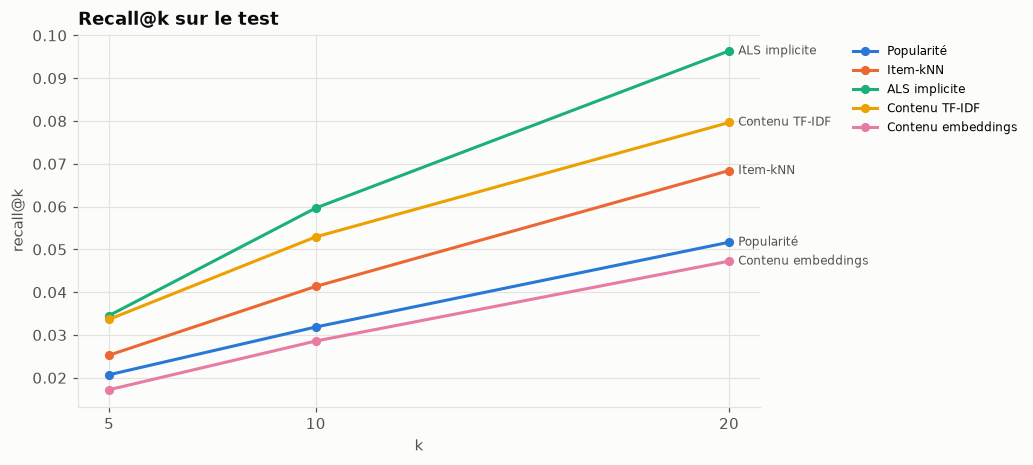

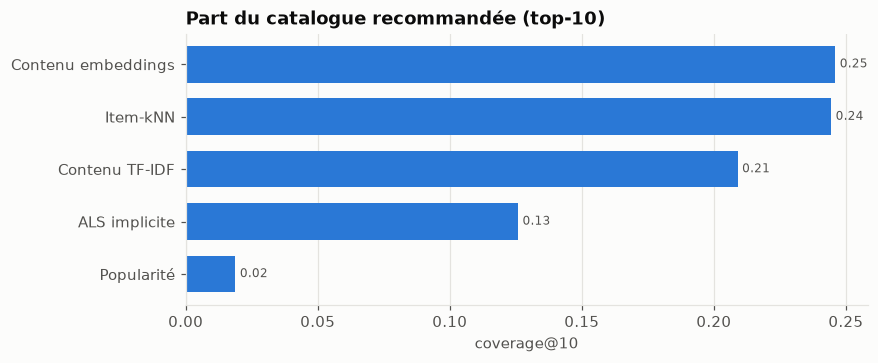

,hyperparamètres retenus,entraînement (s),ms / utilisateur,popularité moyenne du top-10
modèle,,,,
Popularité,relevance_threshold=4.0,0.2241,0.3387,"49,957.1268"
Item-kNN,"k=50, shrinkage=100",92.3335,1.6713,"12,067.9511"
ALS implicite,"factors=64, reg=0.01, alpha=10, iterations=15, relevance_threshold=4.0",111.5858,0.7941,"20,408.3544"
Contenu TF-IDF,"genre_weight=0.2, tag_weight=1.0, title_weight=0.3, aggregation=knn, k=50",6.3147,0.7787,"13,188.5458"
Contenu embeddings,"model=sentence-transformers/all-MiniLM-L6-v2, max_tags=15, aggregation=knn, k=50",4.9481,0.5735,"6,227.9196"


In [12]:
show(model_report.plot_metric_by_k(test, "recall", results["protocol"]["ks"], "Recall@k sur le test"))
show(model_report.plot_metric(test, "coverage@10", "Part du catalogue recommandée (top-10)"))
model_report.cost_table(test).set_index("modèle")

In [13]:
validation = model_report.results_frame(results["validation"])
validation[["label", "params", "ndcg@10", "recall@10", "coverage@10"]].set_index("label")

,params,ndcg@10,recall@10,coverage@10
label,,,,
Contenu TF-IDF,"genre_weight=1.0, tag_weight=0.0, title_weight=0.0, aggregation=knn, k=50",0.0168,0.0060,0.3507
Contenu TF-IDF,"genre_weight=1.0, tag_weight=1.0, title_weight=0.0, aggregation=centroid, k=50",0.0026,0.0014,0.0818
Contenu TF-IDF,"genre_weight=1.0, tag_weight=1.0, title_weight=0.0, aggregation=knn, k=50",0.0571,0.0219,0.2011
Contenu TF-IDF,"genre_weight=0.5, tag_weight=1.0, title_weight=0.0, aggregation=knn, k=50",0.0839,0.0353,0.1918
Contenu TF-IDF,"genre_weight=0.5, tag_weight=1.0, title_weight=0.3, aggregation=knn, k=50",0.0895,0.0375,0.1853
Contenu TF-IDF,"genre_weight=0.2, tag_weight=1.0, title_weight=0.3, aggregation=knn, k=50",0.1028,0.0446,0.1990
Contenu TF-IDF,"genre_weight=0.0, tag_weight=1.0, title_weight=0.0, aggregation=knn, k=50",0.1011,0.0446,0.2008
Contenu embeddings,"model=sentence-transformers/all-MiniLM-L6-v2, max_tags=15, aggregation=centroid, k=50",0.0234,0.0111,0.0466
Contenu embeddings,"model=sentence-transformers/all-MiniLM-L6-v2, max_tags=15, aggregation=knn, k=50",0.0563,0.0247,0.2448


In [14]:
per_user = pd.concat([
    pd.read_parquet(config.paths.artifacts_dir / collaborative.ARTIFACT_DIR / collaborative.PER_USER_FILE)
      .query("model in ['popularity', 'item_knn', 'als_implicit']"),
    pd.read_parquet(artifacts / content.PER_USER_FILE),
], ignore_index=True)
model_report.segment_table(per_user).set_index("historique")

model,utilisateurs,ALS implicite,Contenu embeddings,Item-kNN,Popularité,Contenu TF-IDF
historique,,,,,,
5-50,703,0.1657,0.0516,0.1451,0.1192,0.1205
51-150,1295,0.1548,0.0576,0.1189,0.0880,0.1154
151-400,1872,0.1357,0.0599,0.0978,0.0658,0.1125
401-1000,1610,0.1204,0.0644,0.0826,0.0682,0.1065
> 1000,726,0.1270,0.0713,0.0916,0.0786,0.1028


L'interprétation chiffrée de ces tableaux figure dans le `README.md`, section Sprint 3.